In [1]:
%%javascript

IPython.tab_as_tab_everywhere = function(use_tabs) {
    if (use_tabs === undefined) {
        use_tabs = true; 
    }

    // apply setting to all current CodeMirror instances
    IPython.notebook.get_cells().map(
        function(c) {  return c.code_mirror.options.indentWithTabs=use_tabs;  }
    );
    // make sure new CodeMirror instances created in the future also use this setting
    CodeMirror.defaults.indentWithTabs=use_tabs;

    };

IPython.tab_as_tab_everywhere()

<IPython.core.display.Javascript object>

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

import geopandas as gpd
from geovoronoi import  coords_to_points, voronoi_regions_from_coords

from utils.chrono import Chrono
import glob
import pickle
import seaborn as sns

from matplotlib import rcParams
rcParams.update({'figure.autolayout': True})

from sklearn.ensemble import IsolationForest #1
from sklearn.cluster import DBSCAN #2

from scipy.spatial import Delaunay

from tqdm import tqdm
from datetime import datetime, timedelta

def defaultPlotting():
	sns.set_context("talk")
	#sns.set(rc={"font.size":20,"axes.titlesize":20,"axes.labelsize":20})#'figure.figsize':(11.7,8.27),
	
defaultPlotting()

do_pickle = False

# GIS Shenzen

In [3]:
# files = glob.glob('/Users/abhimishra/Downloads/d4d/senegal/SET2/SET*.CSV')

# print("Num. file: ", len(files))

# if do_pickle:
# 	j=0
# 	for fl in files:
# 		user_data = pd.read_csv(fl)

# 		with open('senegal_data_' + str(j) + '.pickle', 'wb') as handle:
# 			pickle.dump(user_data, handle, protocol=pickle.HIGHEST_PROTOCOL)
# 		j=j+1
# else:
# 	user_data=[]
# 	for j in range(len(files)):
# 		with open('senegal_data_' + str(j) + '.pickle', 'rb') as handle:
# 			user_data.append( pickle.load(handle) )

In [4]:
# antennas = pd.read_csv('/home/tribe/mabhishe/myspace/shenzen_dataset/*')
# antennas = antennas.groupby(['lon','lat']).first().reset_index()

# antennas['wkt'] = antennas.apply(lambda r: 'POINT({} {})'.format(r['lon'], r['lat']), axis=1)
# antennas['geometry'] = gpd.GeoSeries.from_wkt(antennas['wkt'])
# antennas = gpd.GeoDataFrame(antennas).set_crs('epsg:4326').to_crs('epsg:31028')

# antennas['x'] = antennas.geometry.apply(lambda p: p.x)
# antennas['y'] = antennas.geometry.apply(lambda p: p.y)

# with open('senegal_antennas.pickle', 'wb') as handle:
# 	pickle.dump(antennas, handle, protocol=pickle.HIGHEST_PROTOCOL)

# print("{} antennas".format(len(antennas)), antennas['geometry'])

In [43]:
def totimestamp(idt):
	dt = datetime.strptime(idt, "%H:%M:%S")
	td = dt - datetime(1900,1,1)
	return td.total_seconds()
	#return (td.microseconds + (td.seconds + td.days * 24 * 3600) * 10**6) / 1e6

In [66]:
files = glob.glob('/home/tribe/mabhishe/myspace/shenzen_dataset/*-*')
flag=True

for fl in files:
	if flag:
		trajs = pd.read_csv(fl, header=None)
		trajs.columns=["uid", "ts", "lat", "lon"]
# 		print(trajs)
		
		dts = trajs["ts"].values
		for i, dt in enumerate(dts):
			#print(dt)
			dts[i] = totimestamp(dt)
		trajs["ts"] = dts#data["timestamp"].apply(self.totimestamp)
		
		flag=False
	else:
		t1 = pd.read_csv(fl, header=None)
		t1.columns=["uid", "ts", "lat", "lon"]
# 		print(trajs)
		
		dts = t1["ts"].values
		for i, dt in enumerate(dts):
			#print(dt)
			dts[i] = totimestamp(dt)
		t1["ts"] = dts#data["timestamp"].apply(self.totimestamp)
		
		trajs = pd.concat([trajs, t1], ignore_index=True)

# trajs.columns=["uid", "ts", "lat", "lon"]
print(trajs)

            uid       ts        lat         lon
0         55608  26589.0  22.543080  114.114050
1         55635  28394.0  22.660569  114.058843
2         55652  28572.0  22.545350  114.018300
3         55660  26587.0  22.679410  113.817250
4         55690  27160.0  22.550290  114.120250
...         ...      ...        ...         ...
11180925  49933  84440.0  22.672310  114.041100
11180926  49934  81262.0  22.572452  113.865612
11180927  49934  82198.0  22.581420  113.855190
11180928  49934  83981.0  22.581420  113.855190
11180929  49935  83608.0  22.557790  114.156210

[11180930 rows x 4 columns]


In [67]:
# trajs1 = trajs.groupby(['lon','lat']).first().reset_index()

trajs['wkt'] = trajs.apply(lambda r: 'POINT({} {})'.format(r['lon'], r['lat']), axis=1)
trajs['geometry'] = gpd.GeoSeries.from_wkt(trajs['wkt'])
trajs = gpd.GeoDataFrame(trajs).set_crs('epsg:4326').to_crs('epsg:3857')

trajs['x'] = trajs.geometry.apply(lambda p: p.x)
trajs['y'] = trajs.geometry.apply(lambda p: p.y)

In [68]:
print(trajs)

            uid       ts        lat         lon                          wkt  \
0         55608  26589.0  22.543080  114.114050    POINT(114.11405 22.54308)   
1         55635  28394.0  22.660569  114.058843  POINT(114.058843 22.660569)   
2         55652  28572.0  22.545350  114.018300     POINT(114.0183 22.54535)   
3         55660  26587.0  22.679410  113.817250    POINT(113.81725 22.67941)   
4         55690  27160.0  22.550290  114.120250    POINT(114.12025 22.55029)   
...         ...      ...        ...         ...                          ...   
11180925  49933  84440.0  22.672310  114.041100     POINT(114.0411 22.67231)   
11180926  49934  81262.0  22.572452  113.865612  POINT(113.865612 22.572452)   
11180927  49934  82198.0  22.581420  113.855190    POINT(113.85519 22.58142)   
11180928  49934  83981.0  22.581420  113.855190    POINT(113.85519 22.58142)   
11180929  49935  83608.0  22.557790  114.156210    POINT(114.15621 22.55779)   

                                  geome

In [139]:
# from data_loader.spatial_hierarchy import SpatialHierarchy
# linkage = 'ward'
# spatial_hierarchy = SpatialHierarchy()
# spatial_hierarchy.create_hierarchy(antennas, id_col='site_id', geom_col='geometry', linkage=linkage)


In [140]:
# spatial_hierarchy.save_hierarchy('/Users/benoit/Desktop/Pro/211031-Madrid/out/spatial_hierarchy_senegal.p')

## GIS viz
* Antennas are points
* Computing Voronoi tesselation
* Set geopandas's country borders as a limit for the tesselation

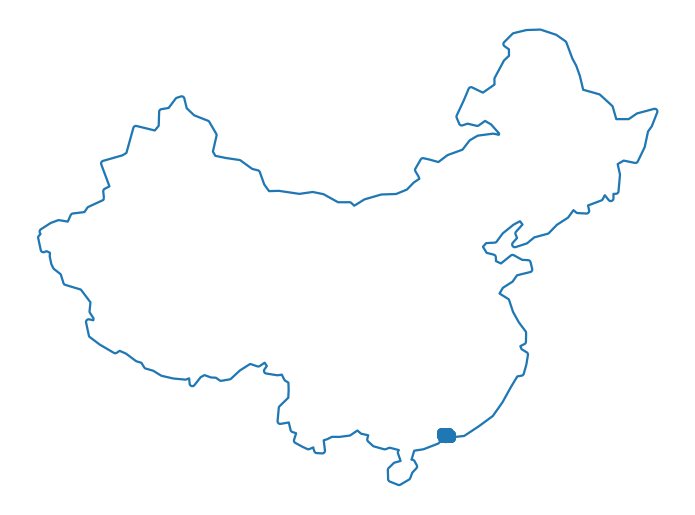

In [69]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres')).to_crs('epsg:3857')
sen_geom_df = world[world['iso_a3']=='CHN'].buffer(30000)
sen_geom = sen_geom_df.iloc[0]

fig, ax = plt.subplots(figsize=(10,10))
trajs.plot(ax=ax)
sen_geom_df.boundary.plot(ax=ax)
ax.axis(False)
plt.show()

In [71]:
trajs.drop(["lon", "lat", "wkt", "geometry"], axis=1, inplace=True)

In [72]:
print(trajs)

            uid       ts             x             y
0         55608  26589.0  1.270312e+07  2.576855e+06
1         55635  28394.0  1.269697e+07  2.591021e+06
2         55652  28572.0  1.269246e+07  2.577128e+06
3         55660  26587.0  1.267008e+07  2.593294e+06
4         55690  27160.0  1.270381e+07  2.577724e+06
...         ...      ...           ...           ...
11180925  49933  84440.0  1.269500e+07  2.592438e+06
11180926  49934  81262.0  1.267546e+07  2.580395e+06
11180927  49934  82198.0  1.267430e+07  2.581476e+06
11180928  49934  83981.0  1.267430e+07  2.581476e+06
11180929  49935  83608.0  1.270781e+07  2.578628e+06

[11180930 rows x 4 columns]


In [73]:
with open('shenzen_trajs.pickle', 'wb') as handle:
	pickle.dump(trajs, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [142]:
# #pts_filtered = [p for p in coords_to_points(np.array([antennas.x, antennas.y]).T) if p.within(sen_geom)]

# #print(pts_filtered, antennas.x)

# # Voronoying stuff
# poly_shapes, pts = voronoi_regions_from_coords(np.array([antennas.x, antennas.y]).T,
#                                                sen_geom)

# # Parsing into a nice dataframe. pts[k][0] is the row nb, not the antenna id
# voronoi_map = gpd.GeoDataFrame([[pts[k][0], poly_shapes[k]] for k in poly_shapes.keys()],
#                                columns=['site_id', 'geometry']).set_crs('epsg:31028').sort_values('site_id').reset_index(drop=True)

# # finding the true antenna id of each row
# voronoi_map = voronoi_map.merge(antennas[['site_id']], left_on='site_id', right_index=True, suffixes=('_tmp', ''))

# print(voronoi_map)

      site_id_tmp                                           geometry  site_id
0               0  POLYGON ((207410.468 1658440.938, 228095.246 1...        1
1               1  POLYGON ((220258.088 1663979.204, 227989.991 1...        2
2               2  POLYGON ((227816.356 1629681.519, 224900.736 1...        3
3               3  POLYGON ((228489.681 1631980.013, 228681.778 1...        4
4               4  POLYGON ((228216.370 1630248.062, 228681.778 1...        5
...           ...                                                ...      ...
1661         1661  POLYGON ((912122.385 1400492.388, 910828.840 1...     1665
1662         1662  POLYGON ((896811.020 1433505.931, 874093.350 1...     1664
1663         1663  POLYGON ((913236.701 1409150.335, 877554.362 1...     1661
1664         1664  POLYGON ((910828.840 1399956.922, 876945.905 1...     1663
1665         1665  POLYGON ((883382.015 1347343.393, 883875.512 1...     1666

[1666 rows x 3 columns]


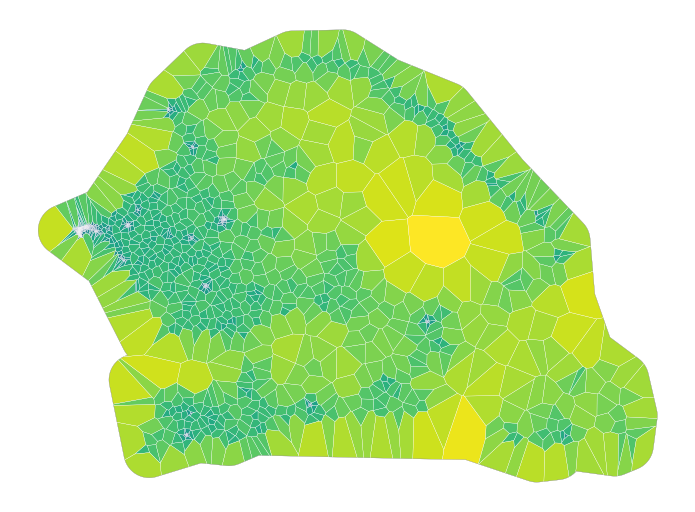

In [143]:
# voronoi_map['colorid'] = np.log(voronoi_map.area)

# fig, ax = plt.subplots(figsize=(10,10))
# sen_geom_df.boundary.plot(ax=ax, color='k', linewidth=0.2)
# #antennas.plot(ax=ax)
# voronoi_map.boundary.plot(ax=ax, color='w', linewidth=0.2)
# voronoi_map.plot(ax=ax, column='colorid')
# ax.axis(False)
# plt.show()

### Visualizing hierarchy

In [144]:
# spatial_hierarchy.set_map(voronoi_map)

In [145]:
# to_plot = []
# to_plot_next = [spatial_hierarchy.gis_root]
# depth = 0
# while len(to_plot) != len(to_plot_next):
#     to_plot = to_plot_next
#     depth+=1
#     to_plot_df = gpd.GeoDataFrame([[node.name, node.geometry, node.parent_name, node.agg_level] for node in to_plot], 
#                  columns=['ci', 'geometry', 'parent', 'agg_level'])
    
#     fig, ax = plt.subplots(figsize=(10,10))
    
#     to_plot_df.plot(ax=ax, column='agg_level')
    
#     to_plot_df.boundary.plot(ax=ax, color='w')#, alpha=0.2, linewidth=1)
    
#     ax.axis(False)
#     plt.savefig('/Users/benoit/Desktop/Pro/211031-Madrid/out/gis_hierarchy_Senegal_viz_{}/{}.png'.format(linkage, depth))
    
#     to_plot_next = []
    
#     for n in to_plot:
#         if len(n.children)==0:
#             to_plot_next += [n]
#         else:
#             to_plot_next += n.children
